# Procesamiento de series temporales

El dataset "ocupacion.csv" describe las medidas ambientales de una habitación con el objetivo de predecir si está ocupada o no.

Hay 20.560 datos medidos con una frecuencia de muestreo de un minuto, tomados a lo largo de unas semanas. El set de datos contiene 7 variables.

**Variables del dataset**
- date: year-month-day hour:minute:second
- Temperature (Temperatura), en Celsius
- Relative Humidity (Humedad relativa) en %
- Light (Luminosidad), en Lux
- CO2, en ppm
- Humidity Ratio (Raio de humedad), derivado de la temperatura y la humedad relativa, en kgwater-vapor/kg-air
- Occupancy, 0 or 1, 0 para habitación NO ocupada, 1 para habitación ocupada

Preparar los datos para su análisis y modelización.

Las credenciales de la fuente de datos pertenecen a Luis Candanedo de UMONS.

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
df = pd.read_csv("dataset.csv", header=0)

In [30]:
df2 = df.copy()

In [31]:
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-11 14:48:00,21.7600,31.133333,437.333333,1029.666667,0.005021,1
2,2015-02-11 14:49:00,21.7900,31.000000,437.333333,1000.000000,0.005009,1
3,2015-02-11 14:50:00,21.7675,31.122500,434.000000,1003.750000,0.005022,1
4,2015-02-11 14:51:00,21.7675,31.122500,439.000000,1009.500000,0.005022,1
5,2015-02-11 14:51:59,21.7900,31.133333,437.333333,1005.666667,0.005030,1


In [44]:
df.dtypes

date              object
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

In [45]:
#Cambiamos el formato de la fecha 
df["date"] = pd.to_datetime(df["date"])

In [46]:
df.dtypes

date             datetime64[ns]
Temperature             float64
Humidity                float64
Light                   float64
CO2                     float64
HumidityRatio           float64
Occupancy                 int64
dtype: object

In [32]:
df.isna().sum()

date              0
Temperature      44
Humidity          9
Light             8
CO2              23
HumidityRatio    18
Occupancy         0
dtype: int64

In [33]:
len(df)

9752

Tenemos como máximo 44 valores no informados de 9752. ¿Es conveniente eliminar las filas? Podemos, porque estamos ante un problema de clasificación.


In [34]:
df.dropna(inplace=True)
df.isna().sum()

date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

Analicemos la correlación entre variables para ver la dependencia entre ellas.

In [35]:
df.corr(method="pearson")

C:\Users\icalvo\AppData\Local\Temp\ipykernel_4632\2677068142.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr(method="pearson")


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
Temperature,1.000000,-0.472970,0.705877,0.200098,-0.010915,0.522460
Humidity,-0.472970,1.000000,-0.187880,-0.080203,0.884319,-0.088897
Light,0.705877,-0.187880,1.000000,0.189482,0.161912,0.914495
CO2,0.200098,-0.080203,0.189482,1.000000,0.042209,0.261481
HumidityRatio,-0.010915,0.884319,0.161912,0.042209,1.000000,0.188791
Occupancy,0.522460,-0.088897,0.914495,0.261481,0.188791,1.000000


Primero, nos fijamos en la correlación de las variables con nuestra variable objetivo:
- Vemos que Humidity, HumidityRatio y CO2 tienen muy baja correlación. En este caso se podrían eliminar.

Ahora nos fijamos en las correlaciones entre cada par de variables. No vemos que haya variables con muy alta correlación (1 o cercano a 1), por lo que no eliminaremos ninguna otra variable.

In [36]:
# Dataset final
dataset_final = df[["date", "Temperature", "Light", "Occupancy"]]
dataset_final.head()

,date,Temperature,Light,Occupancy
1,2015-02-11 14:48:00,21.7600,437.333333,1
2,2015-02-11 14:49:00,21.7900,437.333333,1
3,2015-02-11 14:50:00,21.7675,434.000000,1
4,2015-02-11 14:51:00,21.7675,439.000000,1
5,2015-02-11 14:51:59,21.7900,437.333333,1


¿En el caso de que quisieramos hacer una predicción de si mañana va a estar ocupada la habitación qué cambiaría? 
En este caso si que tendrríamos que informar los missings ya que sino, estaríamos perdiento homogeneidad en la frecuencia de muestreo. Se trataría de una predicción de series temprorales, no de un problema de clasificación.

Teniendo en cuenta que tenemos un dato por minuto y que son condiciones atmosféricas (que no cambian de un minuto a otro) emplearemos los métodos de interpolación lineal o LOCV/NOCF.

In [38]:
#Utilizando interpolación lineal
df2['Temperature_lin']= df2['Temperature'].interpolate(method='linear')
df2['Humidity_lin']= df2['Humidity'].interpolate(method='linear')
df2['Light_lin']= df2['Light'].interpolate(method='linear')
df2['CO2_lin']= df2['CO2'].interpolate(method='linear')
df2['HumidityRatio_lin']= df2['HumidityRatio'].interpolate(method='linear')


In [39]:
#Utilizando LOCV
df2['Temperature_ffill']= df2['Temperature'].fillna(method ='ffill')
df2['Humidity_ffill']= df2['Humidity'].fillna(method ='ffill')
df2['Light_ffill']= df2['Light'].fillna(method ='ffill')
df2['CO2_ffill']= df2['CO2'].fillna(method ='ffill')
df2['HumidityRatio_ffill']= df2['HumidityRatio'].fillna(method ='ffill')

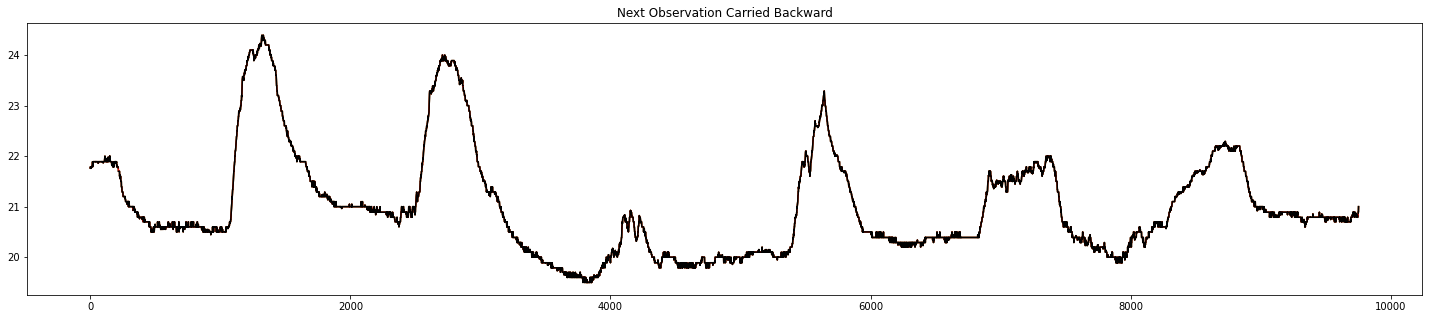

In [40]:
plt.rcParams['figure.figsize']=(25,5)
# plot our time series with imputed values
plt.plot(df2['Temperature_lin'], color='green')
plt.plot(df2['Temperature_ffill'],color='red' )
plt.plot(df2['Temperature'], color='black')

#Plot tittle
plt.title('Next Observation Carried Backward')
# show the plot
plt.show()

In [41]:
df2[["date", "Temperature_lin", "Humidity_lin", "Light_lin", "CO2_lin", "HumidityRatio_lin", "Occupancy"]].corr(method="pearson")

C:\Users\icalvo\AppData\Local\Temp\ipykernel_4632\432761291.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df2[["date", "Temperature_lin", "Humidity_lin", "Light_lin", "CO2_lin", "HumidityRatio_lin", "Occupancy"]].corr(method="pearson")


,Temperature_lin,Humidity_lin,Light_lin,CO2_lin,HumidityRatio_lin,Occupancy
Temperature_lin,1.000000,-0.472917,0.705502,0.199661,-0.010408,0.521776
Humidity_lin,-0.472917,1.000000,-0.187441,-0.079225,0.884104,-0.087761
Light_lin,0.705502,-0.187441,1.000000,0.190236,0.162684,0.914547
CO2_lin,0.199661,-0.079225,0.190236,1.000000,0.043196,0.261921
HumidityRatio_lin,-0.010408,0.884104,0.162684,0.043196,1.000000,0.190152
Occupancy,0.521776,-0.087761,0.914547,0.261921,0.190152,1.000000
